# CUB-200-2011 — Data Preprocessing

This notebook loads the CUB-200-2011 dataset from Hugging Face, checks its structure, creates training and validation splits, applies image transformations, and prepares PyTorch DataLoaders.

**Image size:** 224 × 224  
**Training augmentation:** Random horizontal flip  
**Normalization:** ImageNet mean and standard deviation  
**Split:** 80% train / 20% validation from the original training set; the test set remains unchanged.

In [4]:
# Import libraries for data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import PyTorch
import torch
from torch.utils.data import Dataset, DataLoader, Subset

# Import image processing tools
from PIL import Image
from torchvision import transforms

# Import dataset loading and splitting
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# Set a reproducible random seed
RANDOM_STATE = 42
BATCH_SIZE = 32
IMAGE_SIZE = 224

print("PyTorch version:", torch.__version__)
print("Imports completed successfully.")

PyTorch version: 2.14.1+cpu
Imports completed successfully.


## 1. Load the datasets

Load the training and test splits from the two Hugging Face repositories used in this project.

In [5]:
# Load the original training dataset
train_data = load_dataset("Multimodal-Fatima/CUB_train", split="train")

# Load the original test dataset
test_data = load_dataset("Multimodal-Fatima/CUB_test", split="test")

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))
print("Training columns:", train_data.column_names)
print("Test columns:", test_data.column_names)

Training samples: 5994
Test samples: 5794
Training columns: ['image', 'description', 'label', 'file_name', 'id']
Test columns: ['image', 'description', 'label', 'file_name', 'id']


## 2. Inspect the dataset

Confirm that the required fields are available and inspect one example before preprocessing.

In [6]:
# Check that the expected fields exist
required_columns = {"image", "label", "description", "file_name", "id"}

missing_train_columns = required_columns - set(train_data.column_names)
missing_test_columns = required_columns - set(test_data.column_names)

print("Missing training columns:", missing_train_columns)
print("Missing test columns:", missing_test_columns)

# Display one training example's metadata
sample = train_data[0]
print("Label:", sample["label"])
print("Description:", sample["description"])
print("File name:", sample["file_name"])
print("ID:", sample["id"])
print("Image type:", type(sample["image"]))
print("Image size:", sample["image"].size)

Missing training columns: set()
Missing test columns: set()
Label: 0
Description: this bird is brown with a lighter brown crest.
aquatic large bird with long hooked bill, white face, and brown body.
bird has brown body feathers, brown breast feathers, and brown beak
this bird has a white superciliary and brown all around its body with a long bill
this is a brown bird with a white face and a long downward pointing beak.
this bird is brown with white and has a long, pointy beak.
brown duck playing on the lake making a poodle
this bird has wings that are brown and has a long bill
this bird has long brown bill, with a brown body.
this is a medium sized brown bird, with a long pointed bill.

File name: Black_Footed_Albatross_0007_796138.jpg
ID: 0
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (500, 301)


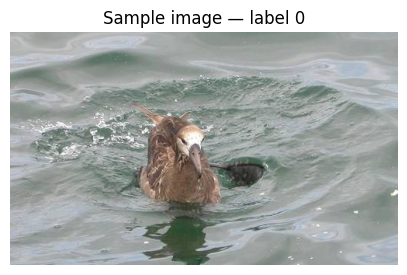

In [7]:
# Display a sample image
plt.figure(figsize=(5, 5))
plt.imshow(train_data[0]["image"].convert("RGB"))
plt.title(f"Sample image — label {train_data[0]['label']}")
plt.axis("off")
plt.show()

## 3. Check labels and class distribution

The labels are expected to represent 200 bird classes, with IDs from 0 to 199.

In [8]:
# Extract labels from both datasets
train_labels = np.asarray(train_data["label"], dtype=int)
test_labels = np.asarray(test_data["label"], dtype=int)

print("Number of training classes:", len(np.unique(train_labels)))
print("Number of test classes:", len(np.unique(test_labels)))
print("Training label range:", train_labels.min(), "to", train_labels.max())
print("Test label range:", test_labels.min(), "to", test_labels.max())
print("Missing training labels:", int(pd.isna(train_labels).sum()))
print("Missing test labels:", int(pd.isna(test_labels).sum()))

assert len(np.unique(train_labels)) == 200, "Expected 200 classes in training data."
assert len(np.unique(test_labels)) == 200, "Expected 200 classes in test data."
assert train_labels.min() == 0 and train_labels.max() == 199
assert test_labels.min() == 0 and test_labels.max() == 199

print("Label checks passed.")

Number of training classes: 200
Number of test classes: 200
Training label range: 0 to 199
Test label range: 0 to 199
Missing training labels: 0
Missing test labels: 0
Label checks passed.


Minimum training images per class: 29
Maximum training images per class: 30
Average training images per class: 29.97
Median training images per class: 30.0


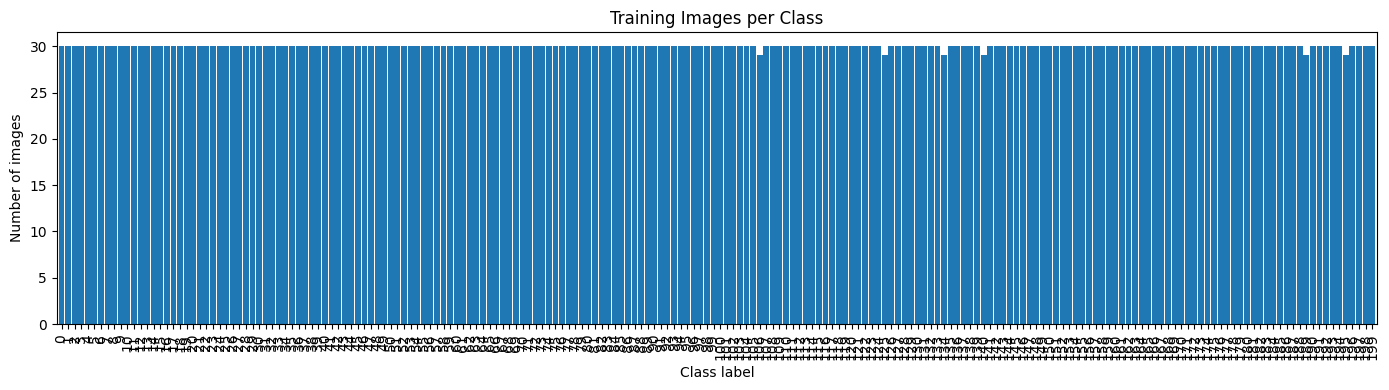

In [9]:
# Summarize the number of images per class
class_counts = pd.Series(train_labels).value_counts().sort_index()

print("Minimum training images per class:", class_counts.min())
print("Maximum training images per class:", class_counts.max())
print("Average training images per class:", round(class_counts.mean(), 2))
print("Median training images per class:", class_counts.median())

plt.figure(figsize=(14, 4))
class_counts.plot(kind="bar", width=0.9)
plt.title("Training Images per Class")
plt.xlabel("Class label")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

## 4. Create training and validation splits

Split the original training set into 80% training and 20% validation. Stratification keeps the class distribution as balanced as possible. The official test set is not split or used for training.

In [10]:
# Create indices for the original training samples
indices = list(range(len(train_data)))

# Split indices into training and validation subsets
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=train_labels
)

print("New training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Official test samples:", len(test_data))

assert len(set(train_indices).intersection(val_indices)) == 0
assert len(train_indices) + len(val_indices) == len(train_data)

print("Train/validation split checks passed.")

New training samples: 4795
Validation samples: 1199
Official test samples: 5794
Train/validation split checks passed.


## 5. Define image transformations

All images are converted to RGB, resized to 224 × 224, converted to tensors, and normalized using ImageNet statistics. Random horizontal flipping is applied only to the training set.

In [11]:
# ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Transformations for training images (includes augmentation)
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Transformations for validation and test images (no random augmentation)
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

print("Image transformations are ready.")

Image transformations are ready.


## 6. Create a PyTorch Dataset class

This class reads an image and its metadata from the Hugging Face dataset and applies the selected image transformation.

In [12]:
class CUBDataset(Dataset):
    def __init__(self, source_data, indices=None, transform=None):
        self.source_data = source_data
        self.indices = list(range(len(source_data))) if indices is None else list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        source_index = self.indices[index]
        sample = self.source_data[source_index]

        image = sample["image"].convert("RGB")
        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "label": int(sample["label"]),
            "description": sample["description"],
            "file_name": sample["file_name"],
            "id": sample["id"]
        }

print("CUBDataset class defined.")

CUBDataset class defined.


## 7. Build the train, validation, and test datasets

Use training augmentation only for the training subset. Validation and test use the same deterministic preprocessing.

In [13]:
train_dataset = CUBDataset(
    source_data=train_data,
    indices=train_indices,
    transform=train_transform
)

val_dataset = CUBDataset(
    source_data=train_data,
    indices=val_indices,
    transform=eval_transform
)

test_dataset = CUBDataset(
    source_data=test_data,
    transform=eval_transform
)

print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

Train dataset size: 4795
Validation dataset size: 1199
Test dataset size: 5794


## 8. Create DataLoaders

DataLoaders create batches for model training and evaluation. Shuffling is enabled for training only.

In [14]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


## 9. Verify a batch

Check the image tensor shape, label shape, and data types. For RGB images, a batch should have the shape `[batch_size, 3, 224, 224]`.

In [15]:
batch = next(iter(train_loader))

print("Image batch shape:", batch["image"].shape)
print("Label batch shape:", batch["label"].shape)
print("Image data type:", batch["image"].dtype)
print("Label data type:", batch["label"].dtype)
print("Example labels:", batch["label"][:10].tolist())

assert batch["image"].ndim == 4
assert batch["image"].shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert batch["image"].dtype == torch.float32
assert batch["label"].dtype == torch.int64

print("Batch verification passed.")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Example labels: [182, 43, 9, 124, 84, 125, 126, 167, 152, 50]
Batch verification passed.


## 10. Final summary

The dataset is now prepared for CNN training. The original training set has been split into training and validation subsets, while the official test set remains separate. Images are resized, normalized, and converted to tensors; training images also receive random horizontal flipping.

In [16]:
print("Preprocessing summary")
print("---------------------")
print(f"Original training samples: {len(train_data)}")
print(f"Training samples:          {len(train_dataset)}")
print(f"Validation samples:        {len(val_dataset)}")
print(f"Test samples:              {len(test_dataset)}")
print(f"Image size:                {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size:                {BATCH_SIZE}")
print(f"Number of classes:         {len(np.unique(train_labels))}")

Preprocessing summary
---------------------
Original training samples: 5994
Training samples:          4795
Validation samples:        1199
Test samples:              5794
Image size:                224 x 224
Batch size:                32
Number of classes:         200
